# Pixel-based Image Classification: Bayes and k-NN from Scratch


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.stats import norm
from collections import Counter

#set random seed (used in kNN sampling)
np.random.seed(42)

## 1. Bayes Classifier
### Load Images, plot histograms, and find parametric models (PDFs)

We will convert the images to Grayscale for simplicity. This allows us to model the pixel intensities as 1D Gaussian (Normal) distributions. 
The parametric model for our Probability Density Function (PDF) is the Gaussian distribution, characterized by two parameters: mean ($\mu$) and standard deviation ($\sigma$).

Forest PDF Parameters: Mean = 65.45, Std = 13.36
Urban PDF Parameters: Mean = 100.98, Std = 35.74


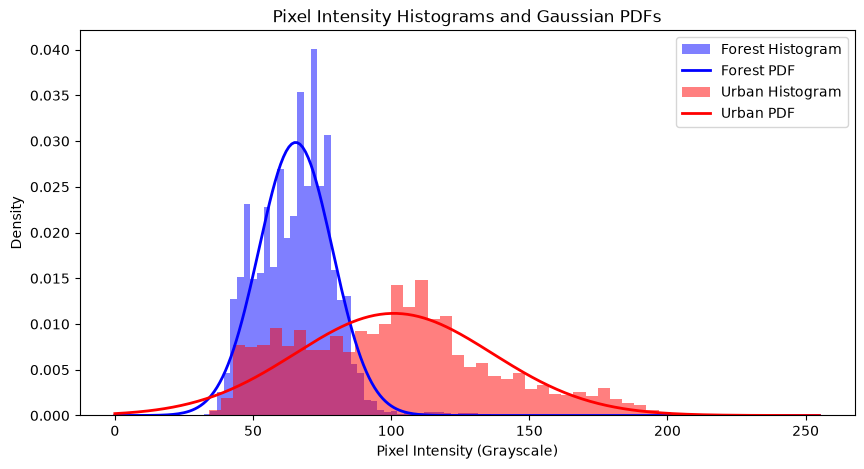

In [2]:
def load_and_preprocess(image_path):
    """Loads an image and converts it to grayscale."""
    img = cv2.imread(image_path)
    if img is None:
        print(f"Warning: {image_path} not found. Using random dummy data.")
        return np.random.randint(0, 255, (100, 100), dtype=np.uint8)
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#images
forest_img = load_and_preprocess('forest.jpg')
urban_img = load_and_preprocess('urban.jpg')
test_img = load_and_preprocess('test_image.jpg')

forest_pixels = forest_img.flatten()
urban_pixels = urban_img.flatten()

mu_forest, std_forest = np.mean(forest_pixels), np.std(forest_pixels)
mu_urban, std_urban = np.mean(urban_pixels), np.std(urban_pixels)

print(f"Forest PDF Parameters: Mean = {mu_forest:.2f}, Std = {std_forest:.2f}")
print(f"Urban PDF Parameters: Mean = {mu_urban:.2f}, Std = {std_urban:.2f}")

plt.figure(figsize=(10, 5))
x_axis = np.arange(0, 256, 1)

plt.hist(forest_pixels, bins=50, density=True, alpha=0.5, color='blue', label='Forest Histogram')
plt.plot(x_axis, norm.pdf(x_axis, mu_forest, std_forest), color='blue', lw=2, label='Forest PDF')

plt.hist(urban_pixels, bins=50, density=True, alpha=0.5, color='red', label='Urban Histogram')
plt.plot(x_axis, norm.pdf(x_axis, mu_urban, std_urban), color='red', lw=2, label='Urban PDF')

plt.title('Pixel Intensity Histograms and Gaussian PDFs')
plt.xlabel('Pixel Intensity (Grayscale)')
plt.ylabel('Density')
plt.legend()
plt.show()

### Bayes test on new image

We use the Maximum A Posteriori (MAP) decision rule. Assuming equal prior probabilities ($P(Forest) = P(Urban) = 0.5$), the Bayes test simplifies to comparing the likelihoods:
If $P(x | Forest) > P(x | Urban)$, classify as Forest (Blue).
Else, classify as Urban (Red).

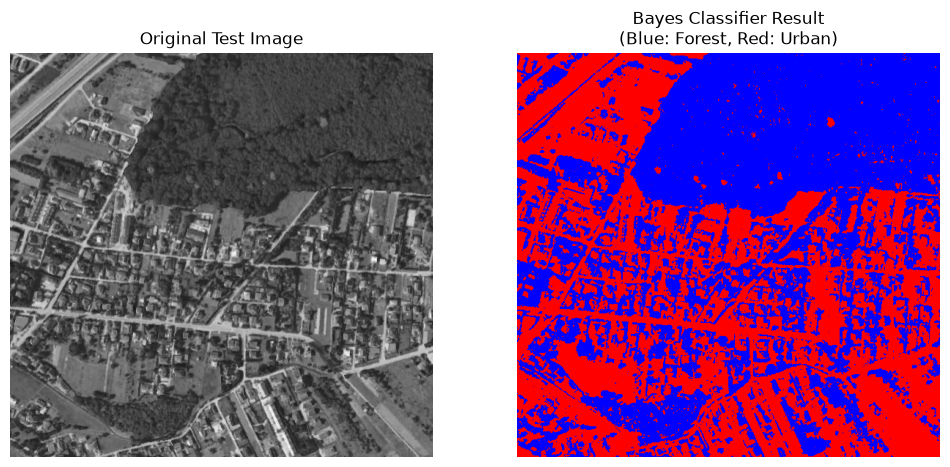

In [3]:
#vectorized Bayes classification
#calculate likelihoods for every pixel in the test image
likelihood_forest = norm.pdf(test_img, mu_forest, std_forest)
likelihood_urban = norm.pdf(test_img, mu_urban, std_urban)

#create an output RGB image (zeros initially)
bayes_result = np.zeros((test_img.shape[0], test_img.shape[1], 3), dtype=np.uint8)

forest_mask = likelihood_forest > likelihood_urban
urban_mask = likelihood_forest <= likelihood_urban

bayes_result[forest_mask] = [0, 0, 255]  # Blue (RGB)
bayes_result[urban_mask] = [255, 0, 0]   # Red (RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(test_img, cmap='gray')
axes[0].set_title('Original Test Image')
axes[0].axis('off')

axes[1].imshow(bayes_result)
axes[1].set_title('Bayes Classifier Result\n(Blue: Forest, Red: Urban)')
axes[1].axis('off')
plt.show()

## 2. k-Nearest Neighbors (k-NN) Classifier
### Design k-NN Classifier from scratch

Since k-NN compares every test pixel to every training pixel, using all pixels is computationally expensive. We will sample a subset of pixels from our training images to serve as our reference dataset.

**Steps:**
1. Sample $N$ pixels from the forest image (Label 0) and $N$ from the urban image (Label 1).
2. For each pixel in the test image, calculate the Euclidean distance to all sampled training pixels.
3. Find the $k$ closest training pixels.
4. Assign the class based on the majority vote among the $k$ neighbors.

In [4]:
num_samples = 500  #number of samples per class to keep computation feasible

sampled_forest = np.random.choice(forest_pixels, num_samples, replace=False)
sampled_urban = np.random.choice(urban_pixels, num_samples, replace=False)

X_train = np.concatenate([sampled_forest, sampled_urban])
y_train = np.concatenate([np.zeros(num_samples), np.ones(num_samples)]) # 0: Forest, 1: Urban

def knn_predict_pixel(pixel_val, k):
    """Predicts the class of a single pixel using k-NN."""
    distances = np.abs(X_train - pixel_val)
    k_indices = np.argsort(distances)[:k]
    k_nearest_labels = y_train[k_indices]
    vote = Counter(k_nearest_labels).most_common(1)[0][0]
    return vote

v_knn = np.vectorize(knn_predict_pixel)


### Present results and compare $k = 1, 3, 5$

We run the k-NN classifier for different values of $k$ and observe how the decision boundaries change.

Running k-NN for k=1...
Running k-NN for k=3...
Running k-NN for k=5...


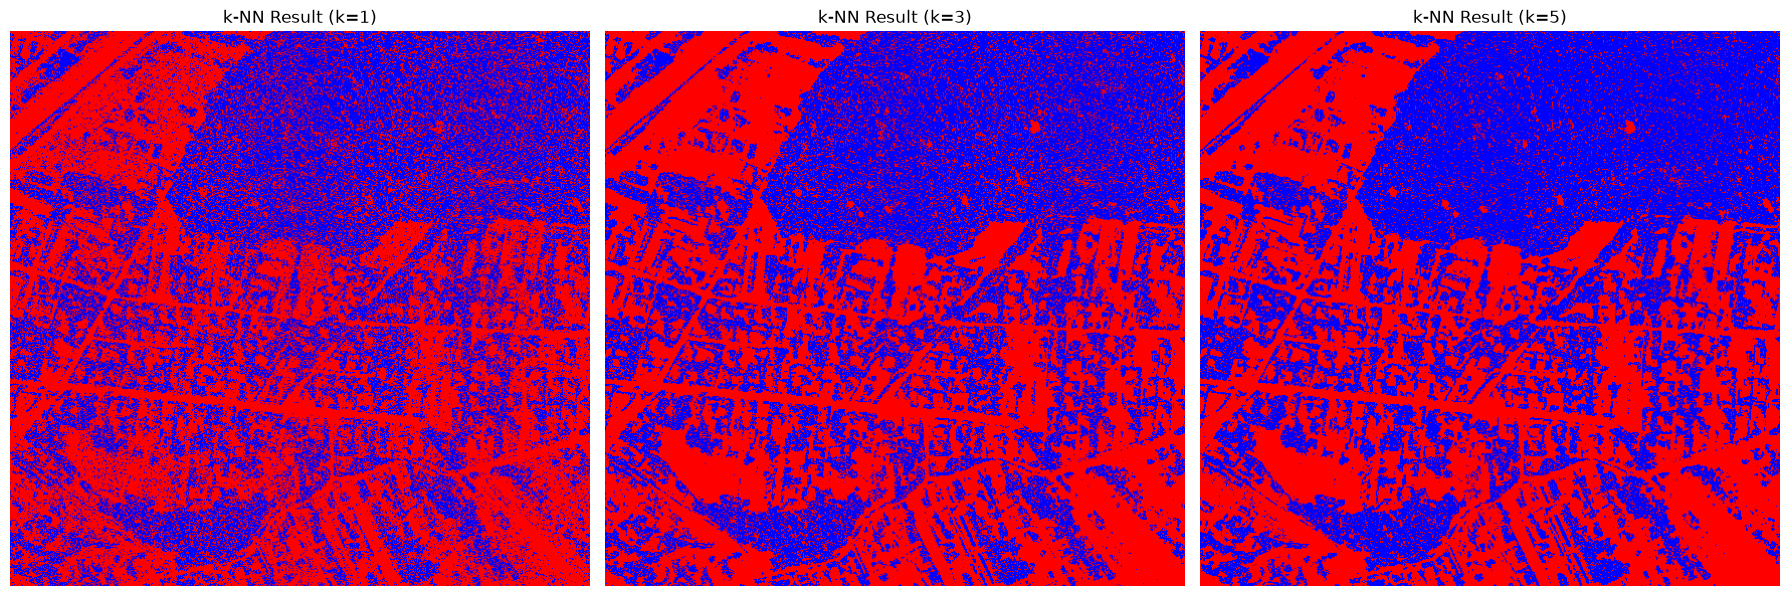

In [5]:
k_values = [1, 3, 5]
knn_results = []

for k in k_values:
    print(f"Running k-NN for k={k}...")
    #labels 0 for forest, 1 for urban
    predictions = v_knn(test_img, k)
    
    result_img = np.zeros((test_img.shape[0], test_img.shape[1], 3), dtype=np.uint8)
    result_img[predictions == 0] = [0, 0, 255] 
    result_img[predictions == 1] = [255, 0, 0] 
    
    knn_results.append(result_img)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, k in enumerate(k_values):
    axes[i].imshow(knn_results[i])
    axes[i].set_title(f'k-NN Result (k={k})')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Differences observed between $k = 1, 3, 5$

* **For k=1:** The image is highly sensitive to noise and looks "grainy." The algorithm assigns a class based on just one nearest pixel from the training data. If there is a single anomalous pixel in the training set (e.g., a darker roof classified as forest), the algorithm blindly trusts it, creating isolated, incorrect classifications on the map.
* **For k=3:** The noise is noticeably reduced. By considering the votes of 3 neighbors, the algorithm starts filtering out some of those individual errors.
* **For k=5:** The color patches (red and blue) become smoother and more cohesive. The majority vote of 5 neighbors acts as a spatial smoothing filter, ignoring single outlier pixels and defining much clearer boundaries between the forest and the urban areas.